# Homework 4: Graph Spectra

We implement the K-eigenvector spectral clustering algorithm of Ng, Jordan and Weiss (NIPS 2001) and use it on the two graphs from the assignment. Before running it on the real data, we try it on two tiny graphs where we already know the answer.

| Graph | Clusters | Why |
| --- | --- | --- |
| example1.dat (physician network) | 4 | Four zero eigenvalues, and the clusters are exactly the four connected components |
| example2.dat (synthetic) | 2 | Eigengap of about 0.545 after the second eigenvalue, and only 113 of 1,209 edges go between the clusters |

Sections: [1. Data](#inputs) | [2. Method](#method) | [3. Warm-up](#warmup) | [4. Results](#experiments) | [5. Duplicate edges](#duplicate-edges) | [6. Timings](#timing) | [7. How to run and AI disclosure](#disclosure)

<a id="inputs"></a>

## 1. Data

| File | Description | Download |
| --- | --- | --- |
| example1.dat | Ron Burt's version of the 1966 Coleman, Katz and Menzel data on physicians in four Illinois towns | [Canvas](https://canvas.kth.se/courses/65339/files/10847669/download?download_frd=1) |
| example2.dat | Synthetic graph | [Canvas](https://canvas.kth.se/courses/65339/files/10847821/download?download_frd=1) |

The files need a KTH login. We keep them in `Coding/datasets/TW4/`, next to the `TW4` folder, and they are not part of the submission ZIP. The algorithm is on page 2 of the [paper](https://ai.stanford.edu/~ang/papers/nips01-spectral.pdf), and the task is described on [Canvas](https://canvas.kth.se/courses/65339/assignments/400855).

The first cell imports our code from `spectral.py` and `main.py` and checks that both data files are in place.

In [1]:
import csv
import json
import platform
import subprocess
import sys
from pathlib import Path

import numpy as np
from IPython.display import Image, Markdown, display
from sklearn.metrics import adjusted_rand_score

# Locate the source when Jupyter starts from the assignment or course directory.
locations = [Path.cwd(), Path.cwd() / "TW4", Path.cwd() / "Coding" / "TW4"]
root = next((path.resolve() for path in locations if (path / "spectral.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Start the notebook from TW4, Coding, or ID2222.")

sys.path.insert(0, str(root))
from main import analyze_graph
from spectral import (
    choose_k,
    cluster_eigenvectors,
    load_graph,
    normalized_spectrum,
    partition_metrics,
)

data_dir = root.parent / "datasets" / "TW4"
output_dir = root / "results" / "notebook"
input_paths = [data_dir / name for name in ("example1.dat", "example2.dat")]
for path in input_paths:
    if not path.is_file():
        raise FileNotFoundError(f"Download {path.name} from Canvas and save it to {data_dir}.")

print(f"Python {platform.python_version()} | Found both input files")
print(", ".join(path.name for path in input_paths))

Python 3.12.16 | Found both input files
example1.dat, example2.dat


Both files are comma-separated edge lists. The row `10,30` is an edge between nodes 10 and 30 with weight 1, and `10,30,2` would give it weight 2. `load_graph` keeps the original node IDs, builds a symmetric adjacency matrix and drops self-loops. If the same pair appears more than once, in either direction, we keep a single edge with the largest weight. Section 5 checks what changes if the duplicates are summed instead.

In [2]:
graphs = {}
table = [
    "| Graph | Raw rows | Edge weights | Repeated directed rows | Self-loops | Asymmetric pairs | Components | Isolates |",
    "| --- | ---: | --- | ---: | ---: | ---: | ---: | ---: |",
]
for path in input_paths:
    raw = np.loadtxt(path, delimiter=",")
    graph = load_graph(path)
    graphs[path.stem] = graph
    stats = graph.stats
    # The loader assigns weight 1 to two-column inputs.
    weights = "1 (default)" if raw.shape[1] == 2 else str(np.unique(raw[:, 2]).tolist())
    table.append(
        f"| {path.stem} | {stats['input_rows']} | {weights} |"
        f" {stats['duplicate_directed_rows']} | {stats['self_loops_removed']} |"
        f" {stats['asymmetric_pairs']} | {stats['components']} | {stats['isolates']} |"
    )

display(Markdown("\n".join(table)))

| Graph | Raw rows | Edge weights | Repeated directed rows | Self-loops | Asymmetric pairs | Components | Isolates |
| --- | ---: | --- | ---: | ---: | ---: | ---: | ---: |
| example1 | 2196 | 1 (default) | 350 | 0 | 0 | 4 | 0 |
| example2 | 2418 | [1.0] | 0 | 0 | 0 | 1 | 0 |

example1 has 2,196 rows, and 350 of them repeat an earlier row in the same direction. Every edge is listed in both directions, so we get $(2196-350)/2=923$ undirected edges. example2 has 2,418 rows, no duplicates and only weight 1, which gives 1,209 edges. Neither graph has self-loops or isolated nodes. example1 is already split into four connected components, so it cannot have fewer than four clusters.

<a id="method"></a>

## 2. Method

$A$ is the $n\times n$ adjacency matrix, $D$ the diagonal matrix of degrees $d_i=\sum_j A_{ij}$, and $K$ the number of clusters. The algorithm in the paper is:

1. Build $S=D^{-1/2}AD^{-1/2}$.
2. Put the eigenvectors of the $K$ largest eigenvalues of $S$ as columns in $X\in\mathbb{R}^{n\times K}$.
3. Scale every row of $X$ to unit length, $Y_{i,:}=X_{i,:}/\lVert X_{i,:}\rVert_2$.
4. Run K-means on the rows of $Y$. Node $i$ gets the cluster of row $i$.

The paper builds $A$ from points with a Gaussian kernel. For a graph we simply use the edge weights. In the code we work with the normalized Laplacian $L_{\rm sym}=I-S$ and take its $K$ smallest eigenvalues. If $Sv=\mu v$ then $L_{\rm sym}v=(1-\mu)v$, so the eigenvectors are the same and only the order is reversed. The eigenvalues have to be sorted by value and not by absolute value, because $S$ has the eigenvalue $-1$ for a bipartite graph and sorting by magnitude would pick it. One of our tests covers this case.

`load_graph` builds $A$, `normalized_spectrum` builds $L_{\rm sym}$ and calls `numpy.linalg.eigh`, and `cluster_eigenvectors` does steps 3 and 4 with scikit-learn's `KMeans`. `spectral_clustering` runs the whole chain for a given K.

### Choosing K

The number of zero eigenvalues of $L_{\rm sym}$ equals the number of connected components $c$. Communities inside a connected graph show up as small nonzero eigenvalues followed by a jump. `choose_k` treats $|\lambda|<10^{-8}$ as zero and picks the K in $c\le K\le\min(10,n-1)$ with the largest gap $\lambda_{K+1}-\lambda_K$. The upper limit of 10 is our own setting (`--max-k`). The largest gap is only a heuristic, so we also compare the cut and modularity for neighbouring values of K.

K cannot be smaller than $c$, because some nodes can then get an all-zero row in $X$ that cannot be normalized. Isolated nodes do not work either since $D^{-1/2}$ is undefined for them. In both cases the code raises an error.

<a id="warmup"></a>

## 3. Warm-up on small graphs

As suggested in the assignment, we first look at the eigenvalues and eigenvectors of two small graphs where the number of communities is obvious: two separate triangles, and two 5-node cliques joined by one edge. Both should give K=2. `show_warmup` prints the five smallest eigenvalues, the first two eigenvectors and the cluster labels. It also asserts that the eigenpairs are correct, that the rows of $Y$ have length one and that the clusters are the expected ones.

In [3]:
def show_warmup(name, adjacency, expected_labels):
    """Show the low-end spectrum and eigenvectors and verify the known groups."""
    values, vectors = normalized_spectrum(adjacency)
    selected_k = choose_k(values, max_k=4)
    labels, embedding = cluster_eigenvectors(vectors, selected_k)

    inverse_sqrt_degrees = 1.0 / np.sqrt(adjacency.sum(axis=1))
    affinity = inverse_sqrt_degrees[:, None] * adjacency * inverse_sqrt_degrees[None, :]
    laplacian = np.eye(len(adjacency)) - affinity
    # Repeated eigenvalues allow different bases, so validate the eigenpair equation.
    np.testing.assert_allclose(laplacian @ vectors, vectors * values, atol=1e-12)
    np.testing.assert_allclose(np.linalg.norm(embedding, axis=1), 1.0)
    assert selected_k == 2
    # ARI checks membership even when the numeric cluster labels are swapped.
    assert adjusted_rand_score(expected_labels, labels) == 1.0

    shown_values = np.where(np.abs(values[:5]) < 1e-12, 0, values[:5])
    gap = values[selected_k] - values[selected_k - 1]
    table = [
        f"**{name}** · First five eigenvalues {np.round(shown_values, 5)} · "
        f"Eigengap {gap:.5f} · K = {selected_k}",
        "",
        "| Node | Entry of v₁ | Entry of v₂ | Cluster label |",
        "| ---: | ---: | ---: | ---: |",
    ]
    for node, (vector, label) in enumerate(zip(vectors, labels), start=1):
        table.append(f"| {node} | {vector[0]:.4f} | {vector[1]:.4f} | {label} |")
    display(Markdown("\n".join(table)))

In [4]:
triangles = np.zeros((6, 6))
triangle = np.ones((3, 3)) - np.eye(3)
# The entries between blocks are zero because the triangles are disconnected.
triangles[:3, :3] = triangle
triangles[3:, 3:] = triangle
show_warmup("Two disconnected triangles", triangles, [0] * 3 + [1] * 3)

bridged_cliques = np.zeros((10, 10))
clique = np.ones((5, 5)) - np.eye(5)
bridged_cliques[:5, :5] = clique
bridged_cliques[5:, 5:] = clique
# Both symmetric entries represent the same undirected bridge.
bridged_cliques[4, 5] = bridged_cliques[5, 4] = 1
show_warmup("Two cliques joined by one edge", bridged_cliques, [0] * 5 + [1] * 5)

**Two disconnected triangles** · First five eigenvalues [0.  0.  1.5 1.5 1.5] · Eigengap 1.50000 · K = 2

| Node | Entry of v₁ | Entry of v₂ | Cluster label |
| ---: | ---: | ---: | ---: |
| 1 | -0.5774 | 0.0000 | 1 |
| 2 | -0.5774 | 0.0000 | 1 |
| 3 | -0.5774 | 0.0000 | 1 |
| 4 | 0.0000 | 0.5774 | 0 |
| 5 | 0.0000 | 0.5774 | 0 |
| 6 | 0.0000 | 0.5774 | 0 |

**Two cliques joined by one edge** · First five eigenvalues [0.     0.0726 1.05   1.25   1.25  ] · Eigengap 0.97740 · K = 2

| Node | Entry of v₁ | Entry of v₂ | Cluster label |
| ---: | ---: | ---: | ---: |
| 1 | 0.3086 | 0.3286 | 1 |
| 2 | 0.3086 | 0.3286 | 1 |
| 3 | 0.3086 | 0.3286 | 1 |
| 4 | 0.3086 | 0.3286 | 1 |
| 5 | 0.3450 | 0.2607 | 1 |
| 6 | 0.3450 | -0.2607 | 0 |
| 7 | 0.3086 | -0.3286 | 0 |
| 8 | 0.3086 | -0.3286 | 0 |
| 9 | 0.3086 | -0.3286 | 0 |
| 10 | 0.3086 | -0.3286 | 0 |

For the two triangles the eigenvalues are 0, 0, 1.5, 1.5, ..., so there are two components and the gap at K=2 is 1.5. With the bridge the graph is connected and only one eigenvalue is zero, but the second one is small (0.0726) and the third jumps to 1.05. The gap of 0.977 again gives K=2. The sign of the second eigenvector separates nodes 1-5 from nodes 6-10, which is the Fiedler vector split, and K-means finds the same two groups.

The tables show the rows of $X$ before normalization. Node 1 in the bridged graph is $(0.3086, 0.3286)$ with length about 0.451, so its row in $Y$ is $(0.685, 0.729)$. The exact numbers can differ on another machine, because eigenvectors are only defined up to sign and a repeated eigenvalue, like the double zero of the triangles, can come with any basis of its eigenspace. This is why the asserts check the eigenpair equation and the partition instead of the coordinates.

We also run the six unit tests from `test_spectral.py` here. They cover the bipartite ordering problem from Section 2, non-consecutive node IDs, duplicate rows, invalid input and reordering of the nodes.

In [5]:
test = subprocess.run(
    [sys.executable, "-m", "unittest"],
    cwd=root,
    capture_output=True,
    text=True,
)
if test.returncode != 0:
    # Show the full log on failure to identify the failing assertion.
    raise RuntimeError(test.stdout + test.stderr)

print(next(line for line in test.stderr.splitlines() if line.startswith("Ran ")))
print("All tests passed.")

Ran 6 tests in 0.107s
All tests passed.


<a id="experiments"></a>

## 4. Results on example1 and example2

`main.analyze_graph` computes the spectrum once per graph, picks K with `choose_k`, and then runs K-means for every K in the search range so the values can be compared. Each K is run with five seeds (0 to 4) and 20 K-means initializations per seed. The exported labels come from seed 0 at the selected K. example1 is searched from K=4 because of its four components, and example2 from K=1. For example2 the comparison starts at K=2, since a single cluster trivially has no cut edges. All output files are written to `results/notebook/`.

In [6]:
# Use the CLI's analysis entry point so the calculations match.
summaries = {path.stem: analyze_graph(path, output_dir) for path in input_paths}
table = [
    "| Graph | Nodes | Undirected edges | Selected K | Cluster sizes | Cross-cluster edges | Eigengap |",
    "| --- | ---: | ---: | ---: | --- | ---: | ---: |",
]
for name, summary in summaries.items():
    metrics = summary["selected_metrics"]
    sizes = ", ".join(map(str, metrics["cluster_sizes"]))
    table.append(
        f"| {name} | {summary['nodes']} | {summary['undirected_edges']} |"
        f" {summary['selected_k']} | {sizes} | {metrics['cross_edges']} |"
        f" {summary['selected_eigengap']:.5f} |"
    )
display(Markdown("\n".join(table)))

| Graph | Nodes | Undirected edges | Selected K | Cluster sizes | Cross-cluster edges | Eigengap |
| --- | ---: | ---: | ---: | --- | ---: | ---: |
| example1 | 241 | 923 | 4 | 35, 41, 48, 117 | 0 | 0.16768 |
| example2 | 100 | 1209 | 2 | 45, 55 | 113 | 0.54509 |

All 923 edges of example1 stay inside the four clusters. In example2, 113 of the 1,209 edges (9.35%) go between the two clusters.

Each figure below has five panels: the smallest eigenvalues of $L_{\rm sym}$ with the chosen gap marked, the sparsity pattern of the adjacency matrix with nodes reordered by cluster (red lines are the cluster borders), the sorted second eigenvector, and the mean normalized cut and modularity over the five seeds for each K.

The normalized cut is $\mathrm{Ncut}=\sum_C \mathrm{cut}(C,\bar C)/\mathrm{vol}(C)$, where $\mathrm{vol}(C)$ is the sum of the degrees in cluster $C$. Modularity is the share of edge weight inside the clusters minus the share expected in a random graph with the same degrees. In example2 each cluster has 113 outgoing edges, which gives Ncut of about 0.188, and the modularity is 0.403.

### example1.dat: four disconnected components

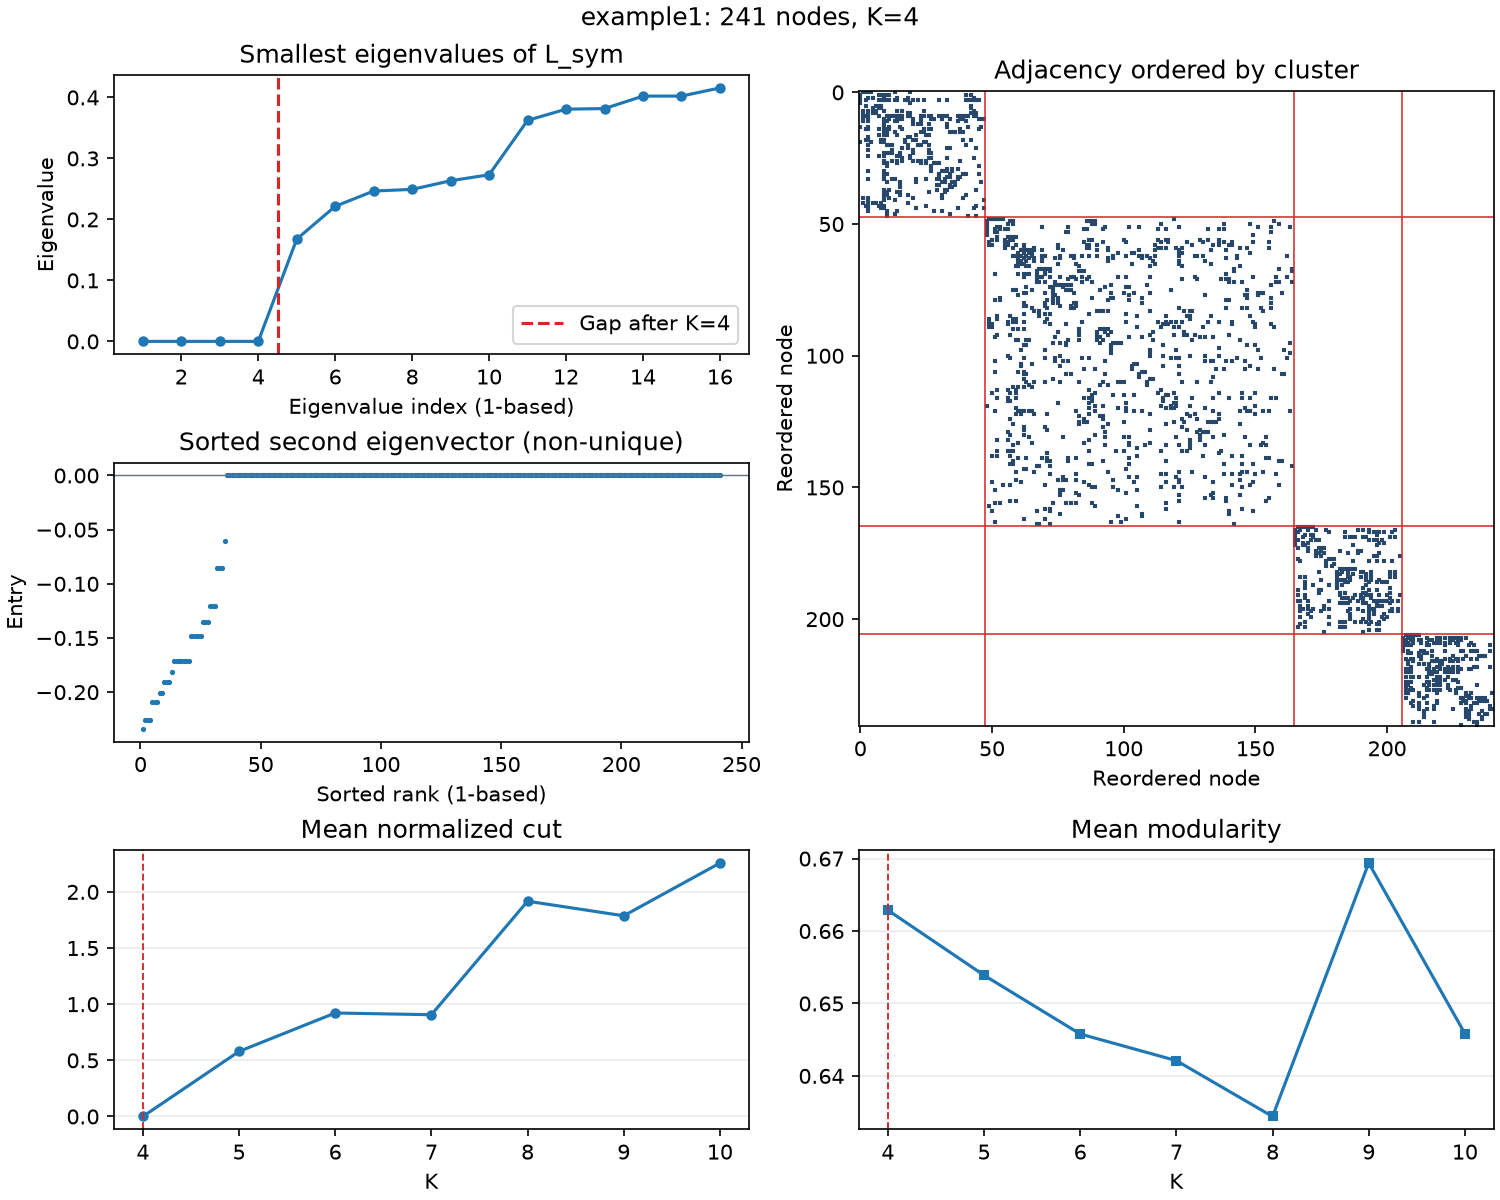

In [7]:
display(
    Image(filename=str(output_dir / "example1_analysis.png"), width=850),
    metadata={"image/png": {"alt": "Four near-zero eigenvalues and four disconnected adjacency blocks"}},
)

The first four eigenvalues are zero up to rounding error and the fifth is 0.168, so K=4. The reordered matrix has four blocks with no edges between them, and the clusters match the connected components exactly (ARI = 1). We cannot tell which cluster is which town, since the file only contains node IDs.

The sorted second eigenvector does not say much for this graph. It belongs to the four-dimensional eigenspace of eigenvalue 0, so the solver may return any vector in that space, and splitting on its sign gives at most two groups anyway. With more than two communities we need several eigenvectors, which is what the K-eigenvector algorithm uses.

### example2.dat: two communities in a connected graph

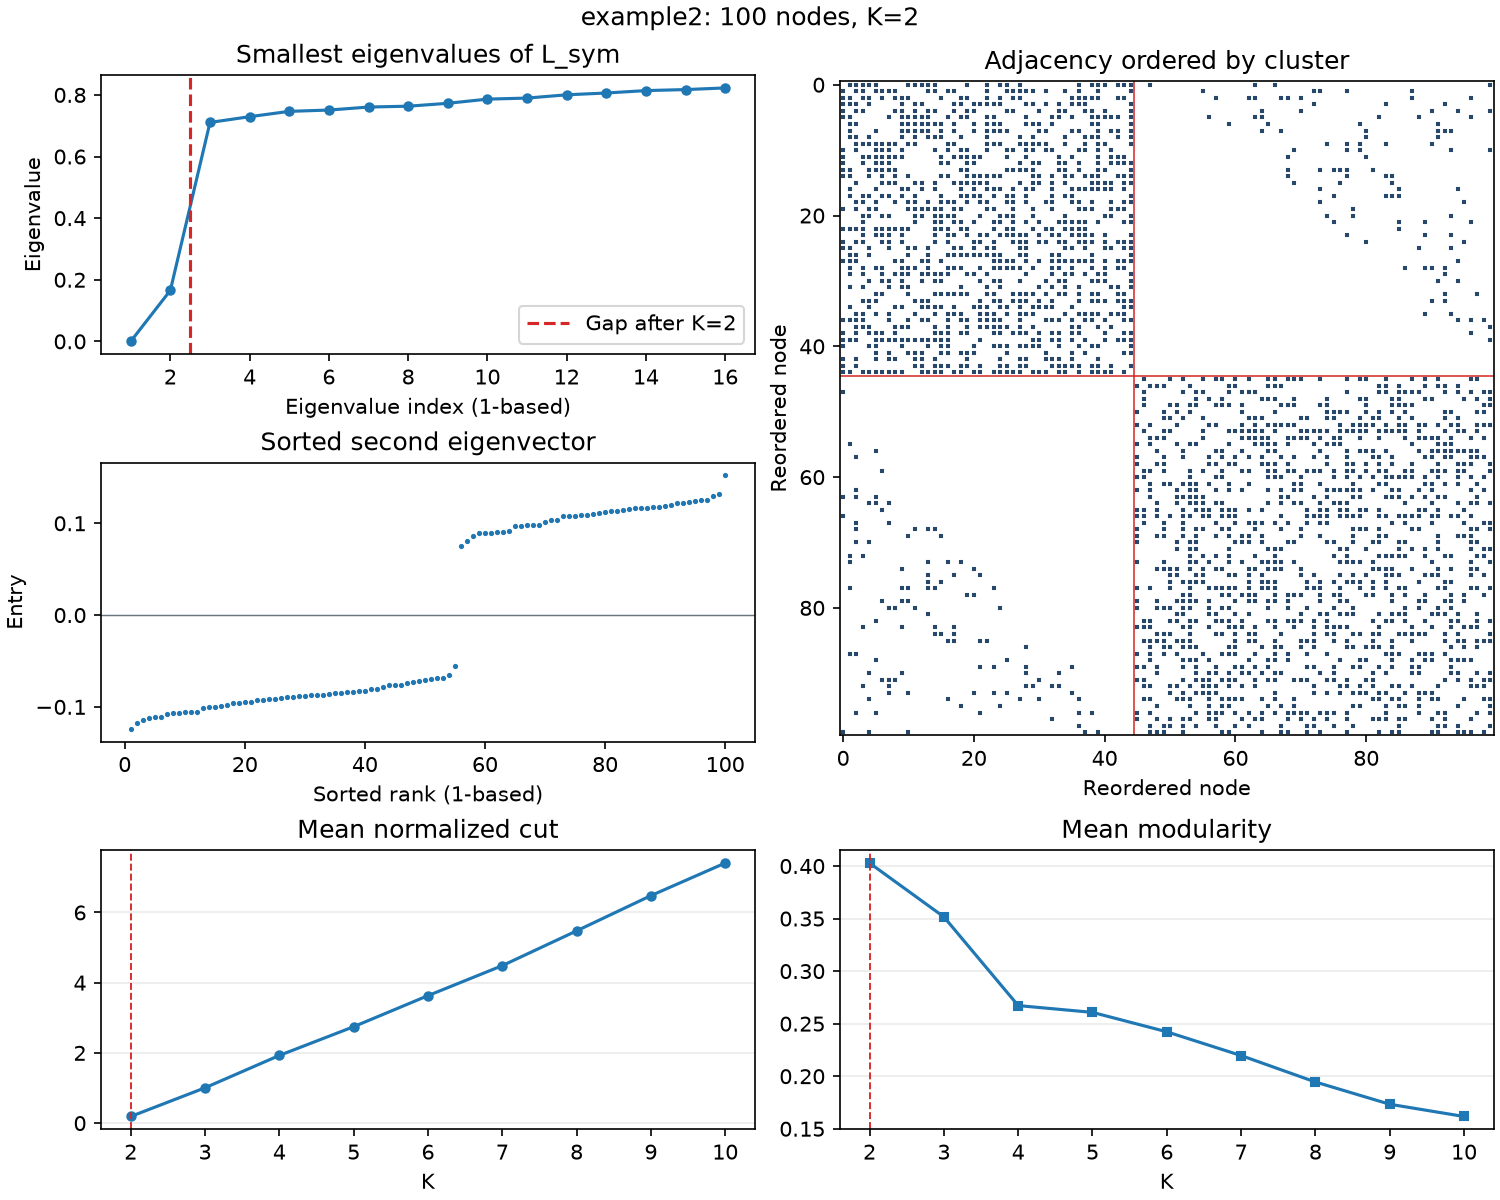

In [8]:
display(
    Image(filename=str(output_dir / "example2_analysis.png"), width=850),
    metadata={"image/png": {"alt": "A large gap after the second eigenvalue and two dense adjacency blocks"}},
)

example2 is connected, so only the first eigenvalue is zero. The second is 0.166 and the third 0.711, a gap of 0.545 that is larger than every other gap up to K=10, so K=2. The reordered matrix has two dense blocks on the diagonal and far fewer edges between them, and the sorted second eigenvector jumps across zero between the two groups. The graph comes without ground-truth labels, so we cannot compute an accuracy.

### Other values of K and other seeds

For each graph we compare the selected K with K+1. The adjusted Rand index (ARI) against seed 0 shows whether different K-means seeds give the same partition. It is 1 when the memberships are identical, whatever numbers the clusters get. The full range of K is in `*_experiments.csv` and in the bottom panels of the figures.

In [9]:
table = [
    "| Graph | K | Mean Ncut | Mean modularity | Min. ARI across seeds |",
    "| --- | ---: | ---: | ---: | ---: |",
]
for name, summary in summaries.items():
    with (output_dir / f"{name}_experiments.csv").open(newline="", encoding="utf-8") as handle:
        records = list(csv.DictReader(handle))

    chosen_k = summary["selected_k"]
    for k in (chosen_k, chosen_k + 1):
        # Compare seeds within each K so results for different cluster counts stay separate.
        group = [row for row in records if int(row["k"]) == k]
        mean_cut = np.mean([float(row["normalized_cut"]) for row in group])
        mean_modularity = np.mean([float(row["modularity"]) for row in group])
        min_ari = min(float(row["ari_to_first_seed"]) for row in group)
        table.append(f"| {name} | {k} | {mean_cut:.5f} | {mean_modularity:.5f} | {min_ari:.4f} |")

display(Markdown("\n".join(table)))

| Graph | K | Mean Ncut | Mean modularity | Min. ARI across seeds |
| --- | ---: | ---: | ---: | ---: |
| example1 | 4 | 0.00000 | 0.66288 | 1.0000 |
| example1 | 5 | 0.57938 | 0.65389 | 0.9968 |
| example2 | 2 | 0.18832 | 0.40283 | 1.0000 |
| example2 | 3 | 1.00580 | 0.35161 | 1.0000 |

At the selected K all five seeds give the same partition. Going from four to five clusters in example1 has to split one of the components, and Ncut rises from 0 to 0.579. For example2, K=3 gives a much higher Ncut (1.006 against 0.188) and a lower modularity (0.352 against 0.403), although the seeds still agree with each other. Agreement between seeds therefore only shows that K-means is stable. The cut and modularity values are what support the K chosen from the eigengap.

<a id="duplicate-edges"></a>

## 5. Duplicate rows in example1

The MATLAB snippet in the assignment, `sparse(col1,col2,1,...)`, adds up entries that land in the same position, so the 350 duplicate rows in example1 would become edges of weight 2. Our loader merges them instead. The data does not say which reading is intended, so we also ran the clustering with summed weights, using the same functions and node order. The comparison reads our original labels back from `example1_labels.csv`.

In [10]:
path = data_dir / "example1.dat"
raw_edges = np.loadtxt(path, delimiter=",", dtype=int)
graph = graphs[path.stem]
node_index = {node: index for index, node in enumerate(graph.nodes)}
weighted = np.zeros_like(graph.adjacency)
# Sum directed records in the same matrix position, as MATLAB sparse does.
for source, target in raw_edges:
    weighted[node_index[source], node_index[target]] += 1
np.testing.assert_array_equal(weighted, weighted.T)

values, vectors = normalized_spectrum(weighted)
weighted_k = choose_k(values)
labels, _ = cluster_eigenvectors(vectors, weighted_k)
comparison = {
    "construction": "sum duplicate directed records as MATLAB sparse does",
    "undirected_weight_sum": float(weighted.sum() / 2),
    "k": weighted_k,
    "selected_eigengap": float(values[weighted_k] - values[weighted_k - 1]),
    **partition_metrics(weighted, labels),
}
path = output_dir / "example1_duplicate_sensitivity.json"
path.write_text(json.dumps(comparison, indent=2), encoding="utf-8")
print(f"Wrote {path.name}")

Wrote example1_duplicate_sensitivity.json


In [11]:
binary = summaries["example1"]
with (output_dir / "example1_labels.csv").open(newline="", encoding="utf-8") as handle:
    binary_labels = [int(row["cluster"]) for row in csv.DictReader(handle)]
# ARI compares membership regardless of label numbering.
agreement = adjusted_rand_score(binary_labels, labels)
assert agreement == 1.0
assert binary["selected_k"] == weighted_k == 4

table = [
    "| Graph construction | Total undirected edge weight | K | Selected eigengap | Modularity |",
    "| --- | ---: | ---: | ---: | ---: |",
    f"| Merge duplicate rows | {binary['undirected_edges']} | {binary['selected_k']} |"
    f" {binary['selected_eigengap']:.5f} | {binary['selected_metrics']['modularity']:.5f} |",
    f"| Sum duplicate rows | {comparison['undirected_weight_sum']:.0f} | {weighted_k} |"
    f" {comparison['selected_eigengap']:.5f} | {comparison['modularity']:.5f} |",
]
display(Markdown("\n".join(table)))
print(f"Partition ARI across constructions = {agreement:.0f}")

| Graph construction | Total undirected edge weight | K | Selected eigengap | Modularity |
| --- | ---: | ---: | ---: | ---: |
| Merge duplicate rows | 923 | 4 | 0.16768 | 0.66288 |
| Sum duplicate rows | 1098 | 4 | 0.19419 | 0.67004 |

Partition ARI across constructions = 1


Summing the duplicates raises the total edge weight from 923 to 1,098 and the eigengap from 0.168 to 0.194. Modularity changes slightly (0.663 to 0.670) because the degrees change. The edges themselves are the same, so there are still four components, K is still 4 and the partition is identical (ARI = 1).

<a id="timing"></a>

## 6. Timings

We use dense matrices and a full eigendecomposition, which needs $O(n^2)$ memory and $O(n^3)$ time. With 241 and 100 nodes this takes a few milliseconds. For a large graph we would switch to a sparse matrix and only compute the first few eigenvectors, for example with `scipy.sparse.linalg.eigsh`, which corresponds to MATLAB's `eigs`. The spectrum is computed once and reused for every K.

The table shows the times from the run in Section 4. "Analysis" covers loading, the eigendecomposition, K-means for all K and seeds, and the metrics. The last column also includes writing the CSV files and the figure. K-means times for each seed are in `*_experiments.csv`.

In [12]:
table = [
    "| Graph | Loading (s) | Eigendecomposition (s) | Analysis (s) | Including output (s) |",
    "| --- | ---: | ---: | ---: | ---: |",
]
for name, summary in summaries.items():
    # Separate analysis time from wall time including figure and table output.
    table.append(
        f"| {name} | {summary['load_seconds']:.4f} |"
        f" {summary['eigendecomposition_seconds']:.4f} |"
        f" {summary['analysis_seconds_excluding_output']:.4f} |"
        f" {summary['total_seconds_including_output']:.4f} |"
    )
display(Markdown("\n".join(table)))

| Graph | Loading (s) | Eigendecomposition (s) | Analysis (s) | Including output (s) |
| --- | ---: | ---: | ---: | ---: |
| example1 | 0.0101 | 0.0184 | 0.5681 | 1.0365 |
| example2 | 0.0114 | 0.0042 | 0.7306 | 1.2871 |

The eigendecomposition is only a small part of the analysis time. Most of it goes to K-means, which runs 7 values of K × 5 seeds for example1 and 9 × 5 for example2, each with 20 initializations.

<a id="disclosure"></a>

## 7. How to run, and AI disclosure

From `Coding/TW4`, with Python 3.10 or newer:

```sh
python -m pip install -r requirements.txt
python -m unittest -v
python main.py
```

`run.ps1` runs `main.py` on Windows. To rerun this notebook, start Jupyter with the same Python environment and run all cells. The notebook writes to `results/notebook/`.

| Argument | Default | Meaning |
| --- | --- | --- |
| `--data-dir` | `../datasets/TW4` | Folder with example1.dat and example2.dat |
| `--output-dir` | `results` | Where the CSV, JSON and PNG files go |
| `--max-k` | `10` | Largest K considered |
| `--seeds` | `0 1 2 3 4` | K-means seeds, labels are exported for the first one |
| `--n-init` | `20` | K-means initializations per seed |

For each graph, `main.py` writes the cluster labels (`*_labels.csv`), the full spectrum (`*_spectrum.csv`), the metrics for every K and seed (`*_experiments.csv`), a summary with input hash, statistics and timings (`*_summary.json`) and the figure (`*_analysis.png`).

### AI disclosure

We used generative AI to help us understand the assignment, review the structure of the algorithm, and improve the documentation and presentation. We wrote and are responsible for the final code, chose the parameters, and ran all experiments and tests ourselves on the dataset above. [Course policy on generative AI](https://canvas.kth.se/courses/65339/pages/use-of-generative-ai)